# Where does the Hessian estimation error enter?
**Controlled diagnostic | November 19, 2026**

**Question:** Why do the finite-sample tree estimates miss the known Hessian even for a noiseless quadratic? Can the individual estimates be improved before averaging?

Use the same depth-2 fitted CART tree as the companion small-tree notebook. Hold the fitted splits fixed and compare four variants: empirical means with geometric spacing/location (original); exact uniform-box means (oracle control); empirical means with empirical spacing; empirical means with empirical spacing and empirical second-moment location.

The true Hessian is used only for the oracle and evaluation, never for the empirical variants. This is a diagnostic on a balanced Cartesian grid, not a proposed estimator for arbitrary designs.

**Why:** Reproduce the same quadratic and depth-2 tree without changing the data or splits.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from itertools import combinations
H_true = np.array([[4.,1.5],[1.5,3.]])
def f(x1,x2):
    return .7-x1+2*x2+2*x1**2+1.5*x1*x2+1.5*x2**2
grid = np.linspace(0,1,11)
X = np.array([(x1,x2) for x1 in grid for x2 in grid])
y = f(*X.T)
def fit_tree(depth, X=X, y=y):
    return DecisionTreeRegressor(max_depth=depth, min_samples_leaf=4, random_state=0).fit(X,y)

tree = fit_tree(2)
print(X.shape,tree.get_depth(),tree.get_n_leaves())

(121, 2) 2 4


**Why:** Keep the original split-gradient and effective-location formulas unchanged.

In [2]:
def get_width(l1, u1, l2, u2, axis):
    if axis == 0:
        return u1 - l1
    elif axis == 1:
        return u2 - l2
    raise ValueError('Invalid split axis')


def gradient_estimate(mean_left, mean_right, width):
    return 2*(mean_right - mean_left)/width


def effective_location(l1, u1, l2, u2, tau, axis):
    if axis == 0:
        m1 = (l1 + tau + u1)/3
        m2 = (l2 + u2)/2
    elif axis == 1:
        m1 = (l1 + u1)/2
        m2 = (l2 + tau + u2)/3
    else:
        raise ValueError('Invalid split axis')
    return np.array([m1, m2])

**Why:** Retrieve the three selected internal nodes and their inherited bounds.

In [3]:
def node_info(tree, path=''):
    t = tree.tree_
    node = 0
    bounds = [0.,1.,0.,1.]
    for side in path:
        axis,tau = t.feature[node],t.threshold[node]
        if axis < 0 or side not in ('L','R'):
            raise ValueError('Invalid node path')
        if side == 'L':
            bounds[2*axis+1] = tau
            node = t.children_left[node]
        else:
            bounds[2*axis] = tau
            node = t.children_right[node]
    axis,tau = t.feature[node],t.threshold[node]
    v = dict(path=path,id=node,axis=axis,tau=tau,bounds=bounds,
             n=t.n_node_samples[node],mean=t.value[node].item())
    if axis >= 0:
        ml = t.value[t.children_left[node]].item()
        mr = t.value[t.children_right[node]].item()
        width = get_width(*bounds,axis)
        v.update(mean_left=ml,mean_right=mr,width=width,
                 g=gradient_estimate(ml,mr,width),
                 m=effective_location(*bounds,tau,axis))
    return v

def node_gradient(tree,path,expected_axis):
    v = node_info(tree,path)
    assert v['axis'] == expected_axis, 'Unexpected splitting axis'
    return v['g'],v['m']

paths = ['', 'L', 'R']
labels = ['Parent', 'Left', 'Right']
for label, path in zip(labels, paths):
    v = node_info(tree, path)
    print(label, 'axis:', v['axis'], 'threshold:', round(v['tau'], 6), 'bounds:', np.round(v['bounds'], 6))
    assert v['axis'] == 1


Parent axis: 1 threshold: 0.55 bounds: [0. 1. 0. 1.]
Left axis: 1 threshold: 0.25 bounds: [0.   1.   0.   0.55]
Right axis: 1 threshold: 0.85 bounds: [0.   1.   0.55 1.  ]


**Why:** Show the same small fitted tree before changing the gradient inputs.

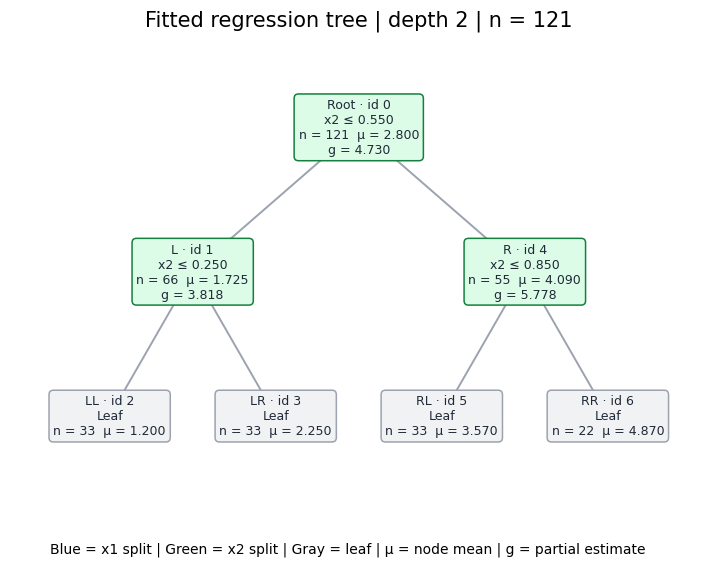

In [4]:
def plot_fitted_tree(tree):
    d = tree.get_depth()
    fig,ax = plt.subplots(figsize=(max(9,1.9*2**d),2*(d+1)))
    def draw(path,lo,hi,level,parent=None):
        v = node_info(tree,path)
        x,y = (lo+hi)/2,-level
        if parent is not None:
            ax.plot([parent[0],x],[parent[1],y],color='#9ca3af',lw=1.4,zorder=1)
        label = f"{path or 'Root'} · id {v['id']}\n"
        if v['axis'] < 0:
            label += f"Leaf\nn = {v['n']}  μ = {v['mean']:.3f}"
            fc,ec = '#f1f2f4','#9ca3af'
        else:
            label += f"x{v['axis']+1} ≤ {v['tau']:.3f}\nn = {v['n']}  μ = {v['mean']:.3f}\ng = {v['g']:.3f}"
            fc,ec = ('#dbeafe','#2563eb') if v['axis']==0 else ('#dcfce7','#15803d')
            draw(path+'L',lo,x,level+1,(x,y))
            draw(path+'R',x,hi,level+1,(x,y))
        ax.text(x,y,label,ha='center',va='center',fontsize=9,color='#1f2937',zorder=2,
                bbox=dict(boxstyle='round,pad=.35',fc=fc,ec=ec,lw=1.1))
    draw('',0,1,0)
    ax.set(xlim=(-.025,1.025),ylim=(-d-.55,.65))
    ax.axis('off')
    ax.set_title(f'Fitted regression tree | depth {d} | n = {tree.tree_.n_node_samples[0]}',fontsize=15)
    fig.text(.5,.015,'Blue = x1 split | Green = x2 split | Gray = leaf | μ = node mean | g = partial estimate',ha='center',fontsize=10)
    plt.show()

plot_fitted_tree(tree)

## 1. Oracle control: replace means, not geometry
For an independent uniform distribution on a rectangle centered at $a$ with widths $w_1,w_2$,
$$\mu_B=f(a)+\frac{H_{11}w_1^2+H_{22}w_2^2}{24}.$$
The centered mixed moment is zero, and each coordinate variance is $w_i^2/12$. The identity uses the known quadratic, so this is a test of the mathematics rather than an estimator for unknown functions.

**Why:** Check whether exact continuous-box means eliminate the original error on the very same split geometry.

In [5]:
def exact_box_mean(bounds):
    l1, u1, l2, u2 = bounds
    a1, a2 = (l1+u1)/2, (l2+u2)/2
    w1, w2 = u1-l1, u2-l2
    return f(a1,a2) + (H_true[0,0]*w1**2 + H_true[1,1]*w2**2)/24

base = {}
for label, path in zip(labels, paths):
    v = node_info(tree, path)
    left = node_info(tree, path+'L')
    right = node_info(tree, path+'R')
    mu_L = exact_box_mean(left['bounds'])
    mu_R = exact_box_mean(right['bounds'])
    g_box = gradient_estimate(mu_L, mu_R, v['width'])
    base[label] = dict(g_original=v['g'],g_box=g_box,m2_geometric=v['m'][1],geometric_spacing=v['width']/2,mean_difference=v['mean_right']-v['mean_left'])
    print(f"{label:6} original={v['g']:.6f} exact={g_box:.6f} m2={v['m'][1]:.6f}")

Parent original=4.730000 exact=4.300000 m2=0.516667
Left   original=3.818182 exact=3.550000 m2=0.266667
Right  original=5.777778 exact=5.150000 m2=0.800000


## 2. Separate spacing error from effective-location error
Let $\Delta E[h(X)]$ denote the right child average minus the left child average of $h(X)$. On this balanced Cartesian grid, the nonsplit coordinate has the same empirical distribution in both children, and within each child the empirical coordinates factorize. For our quadratic and split axis $x_2$,
$$\frac{\Delta E[Y]}{\Delta E[X_2]}=b_2+H_{22}\frac{\Delta E[X_2^2]}{2\Delta E[X_2]}+H_{21}\bar X_1.$$
Thus an empirical location along the split axis is $m_{2,e}=\Delta E[X_2^2]/(2\Delta E[X_2])$. The other coordinate is the common empirical mean. This identity does **not** assume equal child thresholds or sample sizes. It does require the balanced-product design assumptions used here; arbitrary samples can introduce other moment differences.

**Why:** Obtain the actual training observations in each child using sklearn membership, then compute spacing and the empirical location.

In [6]:
membership = tree.decision_path(X).toarray().astype(bool)
for label, path in zip(labels, paths):
    v = node_info(tree,path)
    left_id = tree.tree_.children_left[v['id']]
    right_id = tree.tree_.children_right[v['id']]
    XL, XR = X[membership[:,left_id]], X[membership[:,right_id]]
    # Check the nonsplit coordinate assumptions on the grid.
    assert np.isclose(XL[:,0].mean(), XR[:,0].mean())
    assert np.isclose((XL[:,0]**2).mean(), (XR[:,0]**2).mean())
    for Q in (XL,XR):
        assert np.isclose((Q[:,0]*Q[:,1]).mean(),Q[:,0].mean()*Q[:,1].mean())
    dx = XR[:,1].mean()-XL[:,1].mean()
    assert dx > 0
    m2_emp = ((XR[:,1]**2).mean()-(XL[:,1]**2).mean())/(2*dx)
    base[label]['empirical_spacing'] = dx
    base[label]['g_empirical'] = base[label]['mean_difference']/dx
    base[label]['m2_empirical'] = m2_emp

for label,v in base.items():
    print(f"{label:6} spacing {v['geometric_spacing']:.6f} -> {v['empirical_spacing']:.6f}; m2 {v['m2_geometric']:.6f} -> {v['m2_empirical']:.6f}; g {v['g_original']:.6f} -> {v['g_empirical']:.6f}")

Parent spacing 0.500000 -> 0.550000; m2 0.516667 -> 0.516667; g 4.730000 -> 4.300000
Left   spacing 0.275000 -> 0.300000; m2 0.266667 -> 0.250000; g 3.818182 -> 3.500000
Right  spacing 0.225000 -> 0.250000; m2 0.800000 -> 0.816667; g 5.777778 -> 5.200000


## 3. Compare the same three Hessian contrasts
Only the input gradient and effective coordinate change between variants. We do not pool or refit trees.

**Why:** Show which individual contrasts improve, rather than only comparing their averages.

In [7]:
def H22_contrast(a,b,g_col,m_col):
    return (base[b][g_col]-base[a][g_col])/(base[b][m_col]-base[a][m_col])
methods = {'Original':('g_original','m2_geometric'),'Oracle box means':('g_box','m2_geometric'),'Spacing only':('g_empirical','m2_geometric'),'Spacing + location':('g_empirical','m2_empirical')}
pairs = [('Parent','Left'),('Parent','Right'),('Left','Right')]
results = {k:np.array([H22_contrast(a,b,g,m) for a,b in pairs]) for k,(g,m) in methods.items()}
for k,v in results.items(): print(f'{k:20} {np.round(v,6)}')
assert np.allclose(results['Oracle box means'],H_true[1,1],atol=1e-10,rtol=0)
assert np.allclose(results['Spacing + location'],H_true[1,1],atol=1e-10,rtol=0)

Original             [3.647273 3.69804  3.674243]
Oracle box means     [3. 3. 3.]
Spacing only         [3.2      3.176471 3.1875  ]
Spacing + location   [3. 3. 3.]


## Findings and next question
**Evidence:** On this fixed tree, exact uniform box means recover $H_{22}=3$ for all three contrasts. Changing spacing alone reduces the error; using empirical second moments for the effective location also recovers $3$ on this grid. The original error arises before aggregation, from interpreting discrete means using continuous-box geometry.

**Not established:** This is not proof of unbiasedness on random predictors, noisy responses, adaptively selected trees, nonquadratic functions, or for all Hessian entries. The empirical moments used above simplify because the grid factorizes. In arbitrary data the nonsplit coordinate's mean, second moment and interaction moment may also differ between children.

**Next minimal experiment:** Fit the same quadratic to randomly sampled uniform predictors. Inspect those extra moment differences, then test the empirical-spacing/effective-location variant without using the true Hessian as an input. Compare it with the original estimator on the same selected nodes. If the extra terms are substantial, derive a valid correction before proposing aggregation weights.

**For discussion:** Does using within-node empirical moments provide a better foundation than reducing error through averaging alone? Keep the case-counting and symmetry experiments in the separate small-tree findings notebook.